# Crossmatching SN objects from Lasair with Alerce

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.core.display import HTML
from astropy.time import Time
import sys
import astropy.units as u
from alerce.core import Alerce
import pyvo
import os
from lasair import lasair_client as lasair
from astropy.cosmology import Planck18


In [2]:
pd.set_option('display.max_colwidth', 1000)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)

## Importing from Alerce

Let's initiliaze the client

In [3]:
alerce = Alerce()

And try to query the objects from the LSST. As we cannot filter directly with the query method, we fetch objects and then filter.

> **Note:** `page_size=10000` returns only the **first page** (10 000 objects), not the whole survey. The 230 ALeRCE-SN objects below are therefore a partial sample. This section is just exploration; the real comparison is done with TAP further down.

In [4]:
df_alerce = alerce.query_objects(
    survey="lsst",
    format="pandas",
    page_size=10000, # first page only (not the full survey)
)

In [5]:
df_alerce[df_alerce['oid']==170019695992242795]

,oid,tid,sid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,deltamjd,n_det,n_forced,n_non_det,stellar,class_name,classifier_name,classifier_version,probability,ranking
7216,170019695992242795,1,1,52.823855,-29.691604,0.000003,0.000002,61088.093945,61107.030002,18.936057,8,6,0,None,SN,stamp_classifier_rubin_beta,2.0.1,0.99492,1


In [6]:
df_alerce.sort_values(by=["oid"])

,oid,tid,sid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,deltamjd,n_det,n_forced,n_non_det,stellar,class_name,classifier_name,classifier_version,probability,ranking
7216,170019695992242795,1,1,52.823855,-29.691604,0.000003,0.000002,61088.093945,61107.030002,18.936057,8,6,0,None,SN,stamp_classifier_rubin_beta,2.0.1,0.994920,1
5633,170019696046243879,1,1,54.389515,-27.649993,0.000050,0.000066,61088.097015,61088.097015,0.000000,1,0,0,None,asteroid,stamp_classifier_rubin_beta,2.0.1,0.995295,1
6611,170019696271163443,1,1,61.739193,-48.582798,0.000030,0.000030,61088.098045,61095.058482,6.960436,3,191,0,None,bogus,stamp_classifier_rubin_beta,2.0.1,0.995053,1
240,170019696285843512,1,1,59.094166,-50.106775,0.000117,0.000130,61088.098045,61088.098045,0.000000,1,0,0,None,asteroid,stamp_classifier_rubin_beta,2.0.1,0.997023,1
310,170019696285843559,1,1,59.018816,-50.013608,0.000096,0.000106,61088.098045,61088.098045,0.000000,1,0,0,None,asteroid,stamp_classifier_rubin_beta,2.0.1,0.996996,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55,314051319569580064,1,1,8.888942,-45.898122,0.000018,0.000016,61069.071948,61069.071948,0.000000,1,0,0,None,asteroid,stamp_classifier_rubin_beta,2.0.1,0.997132,1
2532,314051319569580069,1,1,8.905762,-45.877314,0.000019,0.000017,61069.071948,61069.071948,0.000000,1,0,0,None,asteroid,stamp_classifier_rubin_beta,2.0.1,0.996193,1
142,314051319585308693,1,1,8.992712,-45.769705,0.000019,0.000017,61069.071948,61069.071948,0.000000,1,0,0,None,asteroid,stamp_classifier_rubin_beta,2.0.1,0.997066,1
6773,314051319585308700,1,1,9.009446,-45.748947,0.000007,0.000007,61069.071948,61069.071948,0.000000,1,0,0,None,asteroid,stamp_classifier_rubin_beta,2.0.1,0.995020,1


In [7]:
df_alerce = df_alerce[df_alerce['class_name']=='SN']
print(len(df_alerce))

230


In [8]:
df_alerce[['oid','class_name','probability','meanra','meandec']]

,oid,class_name,probability,meanra,meandec
0,170591527609303944,SN,0.997749,305.582233,-18.790921
1,170591547426865168,SN,0.997549,347.099521,-5.778599
2,170591507879297843,SN,0.997428,313.427433,-15.723304
3,170591547735146752,SN,0.997395,347.009369,-3.854436
4,170648622718779938,SN,0.997377,207.309624,-7.442118
...,...,...,...,...,...
9672,170587110901285323,SN,0.994433,329.429441,-21.804329
9690,170591546464797145,SN,0.994430,349.549201,-5.731900
9839,170059326010949663,SN,0.994403,187.247042,7.852851
9894,170591546519322743,SN,0.994391,351.564301,-7.065388


## Matching Lasair objects with Alerce

In [9]:
df_lasair = pd.read_csv('Lasair_LSSTuniqueIDs.csv') #only has the ids

In [10]:
# Connect to the ALeRCE TAP service
tap_service = pyvo.dal.TAPService("https://tap.alerce.online/tap")

# Build the list of Lasair diaObjectIds for the ADQL IN clause
ids_sql = ",".join(f"'{x}'" for x in df_lasair["diaObjectId"].astype(str))

# Query: objects found in ALeRCE + their most likely class (latest stamp classifier)
query = f"""
SELECT
    obj.oid,
    obj.meanra  AS ra, obj.meandec AS dec,
    tax.class_name AS alerce_class
FROM alerce_tap.object AS obj
LEFT JOIN alerce_tap.probability AS prob          -- class probabilities live here
    ON obj.oid = prob.oid AND obj.sid = prob.sid
    AND prob.classifier_id = 3                    -- stamp_classifier_rubin_beta_20260421
    AND prob.ranking = 1                          -- keep only the most likely class
LEFT JOIN alerce_tap.taxonomy AS tax              -- translate class_id -> class name
    ON prob.classifier_id = tax.classifier_id 
    AND prob.class_id = tax.class_id
WHERE obj.sid = 1                                 -- sid = 1: diaObjects (LSST)
  AND obj.oid IN ({ids_sql})
"""

match_alerce = tap_service.search(query, maxrec=1_000_000).to_table().to_pandas()
match_alerce["oid"] = match_alerce["oid"].astype(str)
match_alerce = match_alerce.drop_duplicates(subset=['oid'])

print(len(match_alerce), "of", len(df_lasair), "found in ALeRCE")
print(match_alerce["alerce_class"].value_counts(dropna=False))
match_alerce.head()

1000 of 1000 found in ALeRCE
alerce_class
bogus       596
AGN         280
SN           86
asteroid     37
VS            1
Name: count, dtype: int64


,oid,ra,dec,alerce_class
0,170019696011640884,53.194701,-28.742423,SN
1,170019696255435601,61.968244,-49.664202,bogus
2,170019696256483349,62.034628,-49.402147,bogus
3,170019696256483399,62.080952,-49.282719,bogus
4,170019696266969120,59.886518,-50.665625,bogus


In [11]:
#match_alerce.to_csv('match_alerce.csv',index=False)

With that data we can compare the classifier results from each broker and decide what to do next.

### Some information about Lasair

Sherlock classifes transients by location only. It does not look the image or the light curve.
So what Sherlock actually does is crossmatch against catalogs, so it takes the transient RA and DEC and searches in other catalogues the nearby object. Then decide what each matched source is based on some parameters such as how bright it is (etc). **A typical** match for an alert to be considered as 'SN' is just to be near a galaxy but offset from its center.

### Some information about AleRCE

Alerce classifies with ML. It looks at the images of the alert and the output is a probability for each of the five classes. The highest class gets a 1 ranking.
So what it does is that it looks at the stamps (science, template, diff) and based on that classifies it. A SN probabily is seen as a clean dot in the difference, offset from a galaxy in the template. It actually have for each object five rows with its probability, but the client already selects the first one, but that's why we have to join more tables in the TAP query.

And other important thing about Alerce (and I suppose other brokers) is that an oid is an id for an specific region in the sky, which means that different alerts can have the same oid. This can help us to determine if an alert is really a bogus or other object. If it only appeared once or twice, it might be a bogus. but if it keeps appearing, it might be something else.
For example, ML is not good with bright galaxies, because maybe in the reduction and difference, some spiral arms might not be eliminated, so Alerce counts it as bogus. But it might be a SN or a AGN.


In [12]:
dets = alerce.query_detections(oid=170019695992242795, survey="lsst", format="pandas")
dets[["measurement_id", "mjd", "band"]]

,measurement_id,mjd,band
0,170019695455371857,61088.093945,2
1,170019695723807309,61088.095500,2
2,170019695992242795,61088.097015,2
3,170068069949374531,61099.042416,3
4,170076861332193310,61101.029880,3
5,170085659446870061,61103.036386,3
6,170103251901349898,61107.029563,3
7,170103252035567647,61107.030002,3


In the code above we see that this particular oid have 8 different alerts.

### Next steps
Maybe we should not discard the discrepancies, but better rank them in order of certainty. So if the classification matches in both brokers, it might be easy to match with its host galaxy, as in other surveys there's an object nearby. In the other cases we need to do more analysis.

### First look: how many detections / nights per ALeRCE class?
The two cells below were our first attempt to see whether "being seen many times" helps. Keep these points in mind
when reading them (they are explained in detail in the next section):
* `n_det` depends heavily on the **cadence**. Most of these objects lie in Rubin **Deep Drilling Fields**
  (RA≈53, Dec≈-28 = ECDFS; RA≈58–65, Dec≈-47…-50 = EDFS), which are visited many times per night. So `n_det = 100`
  does not mean "100 different nights". The **number of distinct nights** is the fair measure.
* The "asteroid" class has a median of **114 detections over ~10 days**. A real asteroid moves and cannot be detected
  at the same position on different nights, so this label is clearly wrong for these objects.

In [13]:
query = f"""
SELECT
    obj.oid, obj.meanra AS ra, obj.meandec AS dec,
    obj.n_det, obj.deltamjd,
    tax.class_name AS alerce_class,
    prob.probability AS alerce_prob
FROM alerce_tap.object AS obj
LEFT JOIN alerce_tap.probability AS prob
    ON obj.oid = prob.oid AND obj.sid = prob.sid
    AND prob.classifier_id = 3 AND prob.ranking = 1
LEFT JOIN alerce_tap.taxonomy AS tax
    ON prob.classifier_id = tax.classifier_id AND prob.class_id = tax.class_id
WHERE obj.sid = 1 AND obj.oid IN ({ids_sql})
"""
match_alerce = tap_service.search(query, maxrec=1_000_000).to_table().to_pandas()
match_alerce = match_alerce.drop_duplicates(subset=['oid'])

# How many detections does each class have?
print(match_alerce.groupby("alerce_class")[["n_det", "deltamjd", "alerce_prob"]].median())

# Detections bucketed by class
match_alerce["n_det_bin"] = pd.cut(match_alerce["n_det"], [0, 1, 2, 5, 10, 1e6],
                                   labels=["1", "2", "3-5", "6-10", ">10"])
pd.crosstab(match_alerce["alerce_class"], match_alerce["n_det_bin"])

              n_det  deltamjd  alerce_prob
alerce_class                              
AGN            39.0  6.491937     0.569929
SN             88.5  9.939435     0.694162
VS            102.0  6.036244     0.416976
asteroid      114.0  9.937247     0.856684
bogus           5.0  6.016652     0.620942


n_det_bin,2,3-5,6-10,>10
alerce_class,,,,
AGN,20,25,28,207
SN,7,7,7,65
VS,0,0,0,1
asteroid,7,4,3,23
bogus,144,164,83,205


In [14]:
q = f"""
SELECT oid, COUNT(DISTINCT FLOOR(mjd)) AS n_nights
FROM alerce_tap.detection
WHERE sid = 1 AND oid IN ({ids_sql})
GROUP BY oid
"""
nights = tap_service.search(q, maxrec=1_000_000).to_table().to_pandas()
nights["oid"] = nights["oid"].astype(str)

match_alerce["oid"] = match_alerce["oid"].astype(str)
match_alerce = match_alerce.merge(nights, on="oid", how="left")

match_alerce["nights_bin"] = pd.cut(match_alerce["n_nights"], [0, 1, 2, 4, 1e6],
                                    labels=["1", "2", "3-4", "5+"])
pd.crosstab(match_alerce["alerce_class"], match_alerce["nights_bin"])

nights_bin,1,2,3-4,5+
alerce_class,,,,
AGN,2,27,138,113
SN,0,12,13,61
VS,0,0,0,1
asteroid,0,12,1,24
bogus,3,188,295,110


The night counts confirm it: many "bogus" and "asteroid" objects are detected on **3–5+ different nights**, which
a cosmic ray, a subtraction artefact or an asteroid cannot do. Our previous filters (`n_det >= 3`, `n_nights >= 3`,
veto of `bogus/asteroid` with `prob > 0.8`) were a first step, but:
* `n_det` is cadence-biased (see above);
* the condition `bogus & n_nights <= 2` could never trigger once `n_nights >= 3` was required (it was redundant);
* the veto used the ALeRCE label, but the label alone is not reliable here (see next section).

So we replace those filters with the approach below.

---
# Part 2 – Filtering the Lasair SNe: removing what is certainly *not* a SN

## 2.1 Why the two brokers disagree

Out of 1000 Lasair "SN" objects, the ALeRCE stamp classifier says: **bogus 596, AGN 280, SN 86, asteroid 37, VS 1**.
That does **not** mean that 91 % of them are not SNe. The two classifiers look at completely different information:

| | **Lasair / Sherlock** | **ALeRCE stamp classifier** (`classifier_id = 3`) |
|---|---|---|
| Input | Only the **position** compared with catalogued sources | Only the **image cut-outs** (science, template, difference) of the **first alert** |
| "SN" means | "near a galaxy, but not on a known AGN/star/nucleus" | "a clean point source in the difference image, possibly offset from a galaxy" |
| Blind to | the images and the light curve | the light curve, the other detections, the catalogues |

Neither of them looks at the **light curve**, and neither uses the information that Rubin itself attaches to every
detection. That is the information we add here.

Things the results above already tell us:
1. **ALeRCE is not confident here.** The median top-class probability is 0.57 for AGN, 0.62 for bogus and 0.69 for
   SN. A "bogus with 0.6" can have SN as the second most likely class. Until now we kept only `ranking = 1`, so
   we threw that information away. Below we use the **full probability vector** (`p_SN`, `p_AGN`, `p_bogus`, ...).
2. **"asteroid" is wrong for these objects** (re-detected at the same place on many nights). A single-stamp classifier
   confuses a point source with no visible host with a moving object. This label will **not** be used as a veto.
3. **The time window is short.** Detections span only ~10–20 days (MJD 61069–61107). A SN rises for ~2–3 weeks, so
   many objects are still rising. Filters based on duration or "must fade" would wrongly remove real SNe.

## 2.2 Strategy
Instead of one big boolean mask, we build **one table with one row per object** that contains physically motivated
features, and then:
1. **Hard vetoes**: rules that remove objects which are *almost certainly* not a SN (bogus, variable source, AGN,
   star). Every rejected object keeps a `veto_reason`, so we can audit the decision.
2. **SN score** (0–1) for the survivors, a transparent weighted sum of the features.
3. **Tiers**: Gold / Silver / Bronze / Rejected, to rank candidates by certainty for the host matching.

The guiding principle: **a veto must be safe** (it should almost never remove a real SN). Everything uncertain
goes into the score, not into a veto.

## 2.3 Building the feature table

### (a) ALeRCE: the full probability vector
The `probability` table has one row per (object, class). Without the `ranking = 1` condition we get all five
probabilities and turn them into columns with a pivot.

In [15]:
q = f"""
SELECT prob.oid, tax.class_name, prob.probability, prob.ranking
FROM alerce_tap.probability AS prob
JOIN alerce_tap.taxonomy AS tax
    ON prob.classifier_id = tax.classifier_id AND prob.class_id = tax.class_id
WHERE prob.sid = 1 AND prob.classifier_id = 3
  AND prob.oid IN ({ids_sql})
"""
prob = tap_service.search(q, maxrec=1_000_000).to_table().to_pandas()
prob["oid"] = prob["oid"].astype(str)

# one column per class: p_SN, p_AGN, p_bogus, p_asteroid, p_VS
p = prob.pivot_table(index="oid", columns="class_name", values="probability")
p.columns = ["p_" + c for c in p.columns]
p["alerce_class"] = prob[prob["ranking"] == 1].set_index("oid")["class_name"]

# How often is SN the 2nd most likely class for objects that ALeRCE calls something else?
second = prob[prob["ranking"] == 2].set_index("oid")["class_name"]
print("ALeRCE class -> how many have SN as 2nd choice:")
print(p.assign(second=second).query("alerce_class != 'SN'").groupby("alerce_class")["second"]
      .apply(lambda s: (s == "SN").sum()))
p.head()

ALeRCE class -> how many have SN as 2nd choice:
alerce_class
AGN          36
VS            0
asteroid      4
bogus       124
Name: second, dtype: int64


,p_AGN,p_SN,p_VS,p_asteroid,p_bogus,alerce_class
oid,,,,,,
170019695992242795,0.002390,0.991934,0.001129,0.003703,0.000844,SN
170019696008495213,0.005402,0.974966,0.000827,0.006493,0.012311,SN
170019696010067995,0.002404,0.002149,0.002889,0.525473,0.467085,asteroid
170019696011640884,0.279471,0.583528,0.093402,0.007969,0.035630,SN
170019696024748213,0.777234,0.111427,0.032977,0.003429,0.074933,AGN


### (b) Rubin detections: what each alert tells us
`alerce_tap.detection` only has time/band/position, but `alerce_tap.lsst_detection` has the full Rubin
`diaSource` record. We join both by `measurement_id`. The columns we use:

| Column | Meaning | Why it matters |
|---|---|---|
| `isnegative` | the source is **fainter** than in the template (negative difference flux) | A SN only **adds** light to the galaxy. If the source is fainter now than in the template, it was brighter before → **variable** source (AGN, variable star) or a bad subtraction |
| `reliability` | Rubin's own real/bogus ML score (0 = bogus, 1 = real) | Independent of ALeRCE, trained on Rubin data. It is computed for **every** detection, not just the first |
| `extendedness` | 0 = point-like, 1 = extended in the difference image | A SN is a point source. Residuals of a bright galaxy (badly subtracted arms or nucleus) are extended |
| `isdipole` | positive + negative lobe next to each other | Typical of a small misalignment between science and template (the classic "bogus" from bright nuclei/stars) |
| `snr` | signal to noise | to compute peak flux / magnitude |

From these we compute per object:
* `n_nights`: number of **distinct nights** with a detection (`floor(mjd - 0.5)` gives one value per Chilean night).
* `n_bands`: number of different filters with a detection.
* `frac_neg`: fraction of detections with negative flux.
* `med_rel`, `max_rel`: median and maximum Rubin reliability.
* `med_ext`: median extendedness. `frac_dipole`: fraction of dipole detections.
* `pos_scatter`: scatter of the detected positions (arcsec). A real fixed source has a small scatter.
* `peak_mag`: the brightest positive detection, in AB mag (Rubin fluxes are in nJy: `m = 31.4 - 2.5 log10(f)`).

In [16]:
q = f"""
SELECT d.oid, d.mjd, d.band, d.ra, d.dec,
       l.psfflux, l.psffluxerr, l.snr, l.isnegative, l.reliability,
       l.extendedness, l.isdipole
FROM alerce_tap.detection AS d
JOIN alerce_tap.lsst_detection AS l
    ON d.oid = l.oid AND d.measurement_id = l.measurement_id
WHERE d.sid = 1 AND d.oid IN ({ids_sql})
"""
det = tap_service.search(q, maxrec=5_000_000).to_table().to_pandas()
det["oid"] = det["oid"].astype(str)
det["night"] = np.floor(det["mjd"] - 0.5)   # one integer per observing night in Chile
print(len(det), "detections for", det["oid"].nunique(), "objects")

g = det.groupby("oid")
feat_det = pd.DataFrame({
    "n_det":       g.size(),
    "n_nights":    g["night"].nunique(),
    "n_bands":     g["band"].nunique(),
    "frac_neg":    g["isnegative"].mean(),
    "med_rel":     g["reliability"].median(),
    "max_rel":     g["reliability"].max(),
    "med_ext":     g["extendedness"].median(),
    "frac_dipole": g["isdipole"].mean(),
    "pos_scatter": g.apply(lambda d: 3600 * np.hypot(
                       np.std(d["ra"] * np.cos(np.deg2rad(d["dec"]))), np.std(d["dec"]))),
})
pos = det[~det["isnegative"] & (det["psfflux"] > 0)]
feat_det["peak_mag"] = 31.4 - 2.5 * np.log10(pos.groupby("oid")["psfflux"].max())
feat_det.describe().T

61716 detections for 1000 objects


,count,mean,std,min,25%,50%,75%,max
n_det,1000.0,61.716000,141.488672,2.000000,3.000000,11.000000,53.000000,1057.000000
n_nights,1000.0,4.383000,3.000219,1.000000,3.000000,4.000000,5.000000,37.000000
n_bands,1000.0,2.354000,1.103586,1.000000,1.000000,2.000000,3.000000,5.000000
frac_neg,1000.0,0.260586,0.366774,0.000000,0.000000,0.019709,0.500000,1.000000
med_rel,1000.0,0.304978,0.216644,0.101485,0.162311,0.221234,0.364338,1.000000
max_rel,1000.0,0.461012,0.271841,0.103439,0.248730,0.361604,0.637551,1.000000
med_ext,970.0,0.521332,0.298960,0.000036,0.257308,0.528549,0.759260,1.000000
frac_dipole,1000.0,0.144517,0.261184,0.000000,0.000000,0.000000,0.200000,0.971429
pos_scatter,1000.0,0.277525,0.148693,0.015943,0.163943,0.251981,0.373148,0.875305
peak_mag,846.0,23.031527,0.826736,19.657940,22.648624,23.161083,23.581726,26.630636


### (c) Forced photometry: is the source *persistently* there?
Alerts are only issued when the source passes the 5σ detection threshold. **Forced photometry** measures the
flux at the object's position in **every** later visit, whether it was detected or not. It is the most honest
test of persistence:

* `fp_frac_pos3`: fraction of forced measurements with flux **> +3σ**. A SN stays bright for weeks, so this should
  be high. A bogus detection (cosmic ray, artefact) is not there in the other images, so the flux is ~0 → low value.
* `fp_frac_neg3`: fraction with flux **< −3σ**. A SN should essentially never be significantly negative. A variable
  source that was bright in the template is.

In [17]:
q = f"""
SELECT f.oid, f.mjd, f.band, l.psfflux, l.psffluxerr
FROM alerce_tap.forced_photometry AS f
JOIN alerce_tap.lsst_forced_photometry AS l
    ON f.oid = l.oid AND f.measurement_id = l.measurement_id
WHERE f.sid = 1 AND f.oid IN ({ids_sql})
"""
fp = tap_service.search(q, maxrec=5_000_000).to_table().to_pandas()
fp["oid"] = fp["oid"].astype(str)
fp["s2n"] = fp["psfflux"] / fp["psffluxerr"]
print(len(fp), "forced-photometry points for", fp["oid"].nunique(), "objects")

g = fp.groupby("oid")["s2n"]
feat_fp = pd.DataFrame({
    "fp_n":         g.size(),
    "fp_frac_pos3": g.apply(lambda s: (s > 3).mean()),
    "fp_frac_neg3": g.apply(lambda s: (s < -3).mean()),
})
feat_fp.describe().T

180174 forced-photometry points for 1000 objects


,count,mean,std,min,25%,50%,75%,max
fp_n,1000.0,180.174000,221.297289,1.0,30.000000,133.000000,207.000000,1174.0
fp_frac_pos3,1000.0,0.366182,0.368240,0.0,0.050209,0.225208,0.695303,1.0
fp_frac_neg3,1000.0,0.171079,0.291857,0.0,0.000742,0.025724,0.189519,1.0


### (d) Light-curve shape: does the flux go up *and* down repeatedly?
A SN light curve is smooth: it rises, peaks and declines once. An AGN or variable star flickers.
For each object we take the band with most detections, average the flux per night, and count how many times
the trend **reverses direction significantly** (a night-to-night change larger than 3σ in the opposite
direction to the previous significant change). `n_rev = 0` (monotonic) or `1` (one peak) is SN-like;
`n_rev >= 2` means at least two turns (up-down-up), which is unusual for a SN in a ~2-week window.

With only ~10–20 days of data this is a weak test, so it is used in the score and **not** as a veto.

In [18]:
def n_reversals(d):
    band = d["band"].value_counts().idxmax()
    d = d[d["band"] == band]
    nightly = d.groupby("night").agg(flux=("psfflux", "mean"),
                                     err=("psffluxerr", lambda e: np.sqrt((e**2).sum()) / len(e)))
    if len(nightly) < 3:
        return np.nan                       # not enough nights to say anything
    dflux = np.diff(nightly["flux"].values)
    derr = np.hypot(nightly["err"].values[1:], nightly["err"].values[:-1])
    step = np.sign(dflux) * (np.abs(dflux) > 3 * derr)   # +1 / -1 significant, 0 otherwise
    step = step[step != 0]
    return int((np.diff(step) != 0).sum()) if len(step) > 1 else 0

feat_lc = det.groupby("oid").apply(n_reversals).rename("n_rev").to_frame()
feat_lc["n_rev"].value_counts(dropna=False).sort_index()

n_rev
0.0    603
1.0     63
2.0     12
3.0      1
5.0      1
9.0      1
NaN    319
Name: count, dtype: int64

### (e) Cross-matches in ALeRCE: stars (Gaia) and AGN hosts (WISE)
ALeRCE cross-matches every LSST object with **Gaia DR3** and **AllWISE** (`alerce_tap.xmatch`, `catid` 1 and 0).
* **Gaia**: if the transient sits (< 1″) on a source that Gaia classifies as a star (`classprob_dsc_combmod_star > 0.9`),
  it is a stellar flare / variable star, not a SN.
* **WISE colour W1 − W2**: hot dust heated by an accreting black hole makes galaxies red in the mid-infrared.
  `W1 − W2 ≥ 0.8` (Stern et al. 2012) is the standard criterion for an **AGN**. WISE has ~6″ resolution, so this
  colour describes the **host galaxy (nucleus)**, not the transient. It is only meaningful when the transient is
  also nuclear (see the Sherlock separation below).

In [19]:
q = f"SELECT oid, catid, dist, oid_catalog FROM alerce_tap.xmatch WHERE sid = 1 AND oid IN ({ids_sql})"
xm = tap_service.search(q, maxrec=1_000_000).to_table().to_pandas()
xm["oid"] = xm["oid"].astype(str)
cats = ",".join(f"'{c}'" for c in xm["oid_catalog"].unique())

wise = tap_service.search(
    f"SELECT oid_catalog, w1mpro, w2mpro FROM alerce_tap.allwise WHERE oid_catalog IN ({cats})",
    maxrec=1_000_000).to_table().to_pandas()
gaia = tap_service.search(
    f"SELECT oid_catalog, classprob_dsc_combmod_star FROM alerce_tap.gaiadr3_source WHERE oid_catalog IN ({cats})",
    maxrec=1_000_000).to_table().to_pandas()

w = xm[xm["catid"] == 0].merge(wise, on="oid_catalog").sort_values("dist").drop_duplicates("oid")
w["w12"] = w["w1mpro"] - w["w2mpro"]
s = xm[xm["catid"] == 1].merge(gaia, on="oid_catalog").sort_values("dist").drop_duplicates("oid")

feat_xm = pd.concat([
    w.set_index("oid")[["w12"]],
    s.set_index("oid")[["dist", "classprob_dsc_combmod_star"]].rename(
        columns={"dist": "gaia_dist", "classprob_dsc_combmod_star": "gaia_pstar"}),
], axis=1)
print(len(w), "objects with an AllWISE counterpart,", (w["w12"] >= 0.8).sum(), "with W1-W2 >= 0.8")
print(len(s), "objects with a Gaia counterpart")
feat_xm.head()

662 objects with an AllWISE counterpart, 22 with W1-W2 >= 0.8
5 objects with a Gaia counterpart


,w12,gaia_dist,gaia_pstar
oid,,,
170028485673222312,0.199,NaN,NaN
170019696433168540,0.321,NaN,NaN
170028485656445055,0.202,NaN,NaN
170028485653299271,0.224,NaN,NaN
170028485670600823,0.026,NaN,NaN


### (f) Lasair: Sherlock context and TNS
Our CSV only has the ids, so we ask Lasair for what Sherlock found (same client as in `query_snIa_lasair.ipynb`;
it needs a Lasair token in the `LASAIR_LSST_TOKEN` or `LASAIR_TOKEN` environment variable):
* `separationArcsec`: distance between the transient and the **centre** of the associated galaxy. This is the
  key number to tell a SN (usually offset) from an AGN / nuclear transient (on the nucleus, < ~0.5″).
* `physical_separation_kpc`, `z` (spectroscopic), `photoZ`: when the redshift is known we can compute the
  **absolute magnitude** of the transient: `M = m_peak − μ(z)`. Normal SNe peak between about −16 and −20.5
  (superluminous SNe up to ~−22.5).
* `tns_name` / TNS `type`: whether somebody reported the object to TNS and whether it was spectroscopically classified.

In [20]:
L = lasair(os.getenv("LASAIR_LSST_TOKEN") or os.getenv("LASAIR_TOKEN"), endpoint="https://api.lasair.lsst.ac.uk/api")

ids = df_lasair["diaObjectId"].astype(str).tolist()
sherlock_rows, tns_rows = [], []
for i in range(0, len(ids), 200):                    # chunks keep the SQL short
    chunk = ",".join(ids[i:i + 200])
    sherlock_rows += L.query(
        """objects.diaObjectId, objects.tns_name,
           sherlock_classifications.catalogue_table_name, sherlock_classifications.catalogue_object_type,
           sherlock_classifications.separationArcsec, sherlock_classifications.physical_separation_kpc,
           sherlock_classifications.z, sherlock_classifications.photoZ, sherlock_classifications.Mag""",
        "objects, sherlock_classifications",
        f"objects.diaObjectId IN ({chunk})", limit=1000)
    tns_rows += L.query(
        "objects.diaObjectId, crossmatch_tns.type AS tns_type",
        "objects, crossmatch_tns",
        f"objects.tns_name = crossmatch_tns.tns_name AND objects.diaObjectId IN ({chunk})", limit=1000)

sherlock = pd.DataFrame(sherlock_rows)
sherlock["oid"] = sherlock.pop("diaObjectId").astype(str)
tns = pd.DataFrame(tns_rows)
tns["oid"] = tns.pop("diaObjectId").astype(str)
feat_las = sherlock.set_index("oid").join(tns.set_index("oid"))
print(len(feat_las), "objects;", feat_las["tns_name"].notna().sum(), "reported to TNS;",
      (feat_las["tns_type"].fillna("") != "").sum(), "with a spectroscopic type")
feat_las["separationArcsec"].describe()

1000 objects; 45 reported to TNS; 1 with a spectroscopic type


count    998.000000
mean       2.801646
std       15.568372
min        0.003000
25%        0.161250
50%        0.383500
75%        0.962500
max      249.085000
Name: separationArcsec, dtype: float64

### (g) Putting everything together
We also compute the absolute magnitude where Sherlock gives a redshift (spectroscopic `z` first, otherwise a
positive `photoZ`). We use the Planck 2018 cosmology and ignore K-corrections and extinction (fine for a
rough ±0.5 mag sanity check).

In [21]:
feat = (match_alerce[["oid", "ra", "dec"]].set_index("oid")
        .join([p, feat_det, feat_fp, feat_lc, feat_xm, feat_las]))

z_best = feat["z"].where(feat["z"] > 0, feat["photoZ"].where(feat["photoZ"] > 0))
feat["z_best"] = z_best
feat["abs_mag"] = feat["peak_mag"] - Planck18.distmod(z_best.fillna(1).values).value
feat.loc[z_best.isna(), "abs_mag"] = np.nan

print(feat.shape)
feat.groupby("alerce_class")[["n_nights", "n_bands", "frac_neg", "med_rel", "med_ext", "frac_dipole",
                              "fp_frac_pos3", "fp_frac_neg3", "separationArcsec", "p_SN", "p_AGN"]].median().T

(1000, 36)


alerce_class,AGN,SN,VS,asteroid,bogus
n_nights,4.000000,6.000000,5.000000,7.000000,3.000000
n_bands,3.000000,3.000000,4.000000,3.000000,2.000000
frac_neg,0.034847,0.000000,0.009804,0.000000,0.069805
med_rel,0.293500,0.560936,0.257366,0.704996,0.182659
med_ext,0.495086,0.157924,0.847027,0.190476,0.613417
frac_dipole,0.000000,0.000000,0.921569,0.000000,0.000000
fp_frac_pos3,0.248226,0.813834,0.353293,0.944238,0.149890
fp_frac_neg3,0.045983,0.006433,0.449102,0.000000,0.039422
separationArcsec,0.191000,0.704500,0.020000,1.185000,0.468000
p_SN,0.057122,0.694162,0.033074,0.007247,0.061440


**Reading the table of medians (per ALeRCE class):**
* The objects ALeRCE calls **SN** have high Rubin reliability, ~0 negative detections, a point-like difference
  image (low extendedness), a high fraction of significant forced photometry and are **offset** from the galaxy
  centre (~0.7″).
* The ALeRCE **"asteroid"** objects look like the SNe in every Rubin feature (reliability, persistence, point-like,
  offset ~1.2″) → they are most probably **real transients without a visible host in the stamp**, not asteroids.
* **bogus** objects have low reliability, extended difference images, and weak forced photometry: most are real
  artefacts, but not all.
* **AGN** objects sit on the galaxy nucleus (median separation ~0.2″), and their persistence is weak.

## 2.4 Look at the distributions before choosing thresholds
Each panel is one feature, split by ALeRCE class (counts normalised per class, so small classes are visible).
The dashed line is the threshold used in the vetoes.

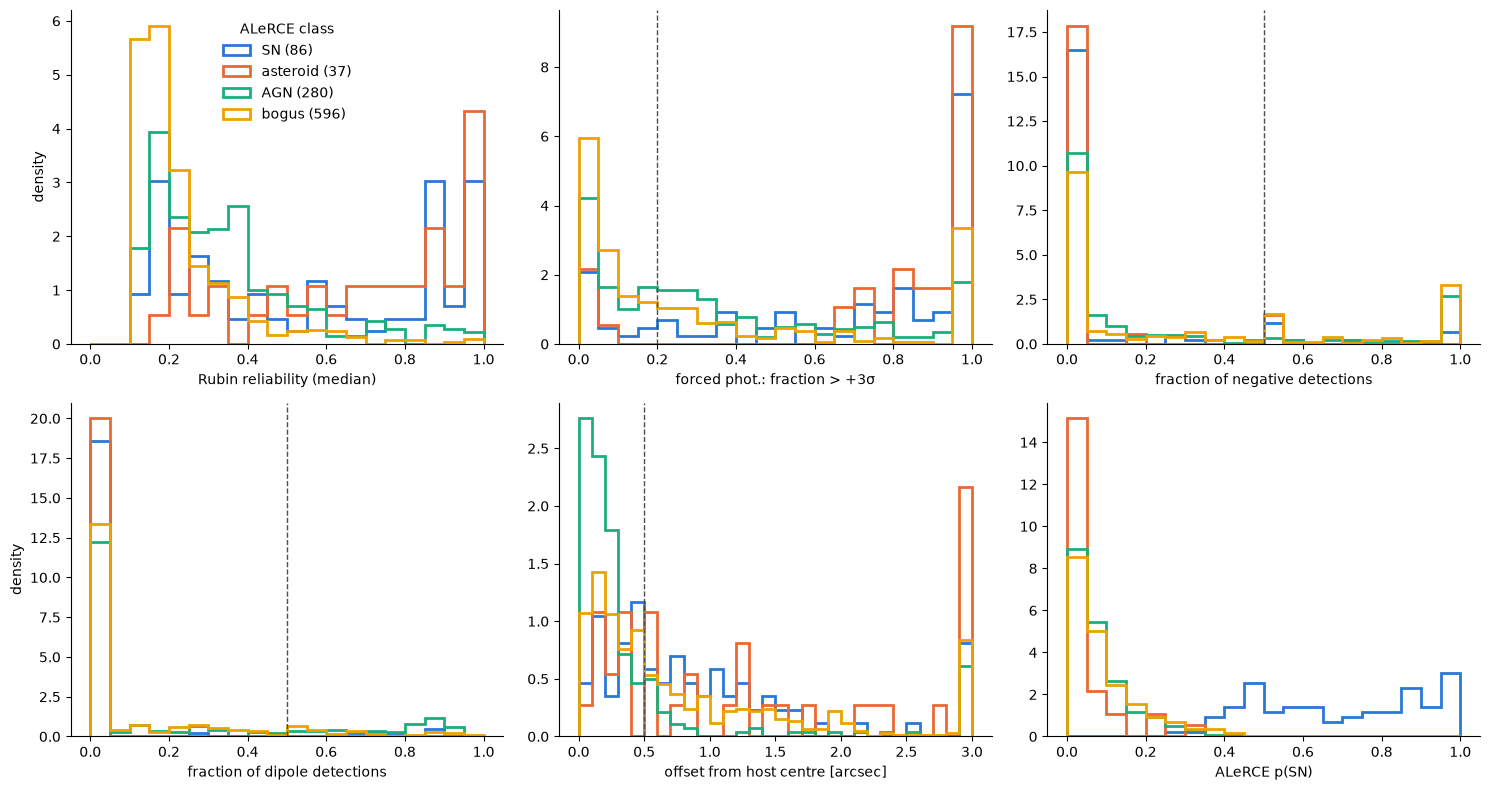

In [22]:
class_order = ["SN", "asteroid", "AGN", "bogus", "VS"]
class_color = {"SN": "#2a78d6", "asteroid": "#eb6834", "AGN": "#1baf7a", "bogus": "#eda100", "VS": "#e87ba4"}
panels = [
    ("med_rel",          np.linspace(0, 1, 21),  None,  "Rubin reliability (median)"),
    ("fp_frac_pos3",     np.linspace(0, 1, 21),  0.2,   "forced phot.: fraction > +3σ"),
    ("frac_neg",         np.linspace(0, 1, 21),  0.5,   "fraction of negative detections"),
    ("frac_dipole",      np.linspace(0, 1, 21),  0.5,   "fraction of dipole detections"),
    ("separationArcsec", np.linspace(0, 3, 31),  0.5,   "offset from host centre [arcsec]"),
    ("p_SN",             np.linspace(0, 1, 21),  None,  "ALeRCE p(SN)"),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, bins, thr, label) in zip(axes.flat, panels):
    for c in class_order:
        x = feat.loc[feat["alerce_class"] == c, col].dropna().clip(bins[0], bins[-1])
        if len(x) > 1:
            ax.hist(x, bins=bins, histtype="step", lw=2, density=True, color=class_color[c], label=f"{c} ({len(x)})")
    if thr is not None:
        ax.axvline(thr, ls="--", color="0.3", lw=1)
    ax.set_xlabel(label)
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].set_ylabel("density"); axes[1, 0].set_ylabel("density")
axes[0, 0].legend(title="ALeRCE class", frameon=False)
plt.tight_layout()
plt.show()

## 2.5 Hard vetoes: what is *certainly* not a SN

Each rule removes a class of contaminant for a clear physical reason. Thresholds are deliberately **conservative**,
because a veto should essentially never remove a real SN. They can be tuned with the plots above.

| Veto | Rule | Why |
|---|---|---|
| `single_night` | `n_nights < 2` | Detected on one night only. We cannot tell a SN from an artefact or a moving object. (Not "certainly not a SN", but unusable for now; it can come back when more data arrive.) |
| `bogus` | `max_rel < 0.3` **and** `fp_frac_pos3 < 0.2` | Rubin never considered **any** detection reliable **and** forced photometry shows no persistent flux. Two independent tests agree it is an artefact. |
| `variable` | `0.2 ≤ frac_neg ≤ 0.8` **or** (`fp_frac_neg3 > 0.2` **and** `fp_frac_pos3 > 0.2`) | The flux goes **both above and below** the template level. A SN only adds flux after explosion, so a source that oscillates around the template is variable (AGN, variable star) or has a systematic subtraction problem. |
| `dipole` | `frac_dipole > 0.5` | Most detections are dipoles = science/template misalignment on a bright compact source (galaxy nucleus, star). |
| `agn_host` | `separationArcsec < 0.5` **and** `W1−W2 ≥ 0.8` | Transient on the nucleus of a galaxy that is an AGN by its infrared colour. |
| `agn_like` | `separationArcsec < 0.3` **and** `p_AGN > 0.5` **and** `fp_frac_pos3 < 0.5` | Nuclear, the stamp looks like an AGN, and the light curve is not persistently bright. A position on the nucleus **alone** is not enough, because nuclear SNe and TDEs exist. |
| `star` | Gaia counterpart < 1″ with `p(star) > 0.9` | Stellar flare / variable star. |

**What we do *not* veto (and why):**
* **The ALeRCE label by itself** (bogus/asteroid/AGN). It is one stamp of the first alert; it enters the score instead.
* **Objects with *only* negative flux** (`frac_neg > 0.8`). A first version vetoed every object with mostly negative
  flux, but this removed e.g. **TNS 2025rha**: a SN from 2025 that is **in the template image** and is now fading,
  so every difference is negative. That is still a SN (just an old one), so it is not vetoed. Its score is low
  anyway (no positive persistent flux), so it ends in Bronze.
* **The luminosity.** We first vetoed `abs_mag > −14` or `< −23`. Looking at the 22 objects it removed, almost all
  had their redshift from a "host" that Sherlock associated at **40–250″**: a big **foreground** galaxy, not the
  real host. The transient is behind it, so `M ≈ −9` is meaningless. The veto even removed TNS 2026euu (score 0.96).
  So the luminosity is now only a **flag** (`lum_flag`): "if this host is right, the transient is too faint/bright
  for a SN, so check the host association". This is useful information for the host-matching step itself.

In [23]:
vetoes = {
    "single_night":  feat["n_nights"] < 2,
    "bogus":         (feat["max_rel"] < 0.3) & (feat["fp_frac_pos3"].fillna(0) < 0.2),
    "variable":      feat["frac_neg"].between(0.2, 0.8)
                     | ((feat["fp_frac_neg3"].fillna(0) > 0.2) & (feat["fp_frac_pos3"].fillna(0) > 0.2)),
    "dipole":        feat["frac_dipole"] > 0.5,
    "agn_host":      (feat["separationArcsec"] < 0.5) & (feat["w12"] >= 0.8),
    "agn_like":      (feat["separationArcsec"] < 0.3) & (feat["p_AGN"] > 0.5) & (feat["fp_frac_pos3"].fillna(0) < 0.5),
    "star":          (feat["gaia_dist"] < 1) & (feat["gaia_pstar"] > 0.9),
}
# not a veto, a warning for the host matching (see the markdown above)
feat["lum_flag"] = np.select([feat["abs_mag"] > -14, feat["abs_mag"] < -23],
                             ["too_faint_for_host_z", "too_bright_for_host_z"], default="")
V = pd.DataFrame(vetoes).fillna(False).astype(bool)   # NaN (missing info) never triggers a veto
feat["veto_reason"] = V.apply(lambda r: ",".join(V.columns[r.values]), axis=1)
feat["vetoed"] = V.any(axis=1)

# how many objects each veto removes, split by ALeRCE class (an object can fail more than one veto)
summary = V.groupby(feat["alerce_class"]).sum().T
summary["total"] = summary.sum(axis=1)
print("Objects failing each veto:")
display(summary)
print(f"Survivors: {(~feat['vetoed']).sum()} of {len(feat)}")
print("Luminosity flags (not vetoed):", feat["lum_flag"].value_counts().to_dict())
pd.crosstab(feat["alerce_class"], feat["vetoed"].map({False: "kept", True: "rejected"}), margins=True)

Objects failing each veto:


alerce_class,AGN,SN,VS,asteroid,bogus,total
single_night,2,0,0,0,3,5
bogus,37,4,0,3,181,225
variable,57,13,1,3,161,235
dipole,61,5,1,0,60,127
agn_host,13,0,0,0,3,16
agn_like,94,0,0,0,0,94
star,1,0,0,0,1,2


Survivors: 493 of 1000
Luminosity flags (not vetoed): {'': 978, 'too_faint_for_host_z': 22}


vetoed,kept,rejected,All
alerce_class,,,
AGN,104,176,280
SN,72,14,86
VS,0,1,1
asteroid,34,3,37
bogus,283,313,596
All,493,507,1000


## 2.6 SN score for the survivors

For every object we combine the evidence into a score between 0 and 1. Each term is already between 0 and 1:

| Term | Weight | SN-like when... |
|---|---|---|
| `p_SN` (ALeRCE, any ranking) | 0.25 | the stamp looks like a SN |
| `med_rel` (Rubin reliability) | 0.20 | Rubin thinks the detections are real |
| `fp_frac_pos3` | 0.25 | the flux is persistently there |
| `1 − frac_neg` | 0.10 | the flux is only positive |
| `offset` = min(separation / 0.5″, 1) | 0.10 | the transient is not on the nucleus |
| `min(n_bands, 3) / 3` | 0.05 | detected in several filters (real astrophysical source, colour information) |
| `smooth` = 1 if `n_rev ≤ 1`, else 0 | 0.05 | the light curve rises/falls smoothly |

The weights are a **choice**, not a fit (we have no labelled training set yet). The idea: the two
independent "is it real and persistent?" tests (Rubin reliability + forced photometry) and the "does it look like a
SN?" test (ALeRCE) carry most of the weight; the rest are tie-breakers. Missing values get a neutral 0.5.

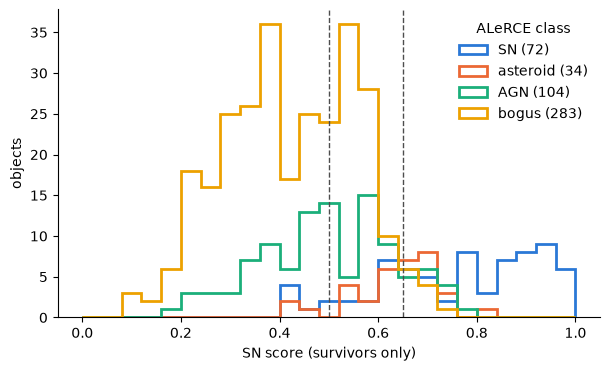

In [24]:
weights = {"p_SN": 0.25, "med_rel": 0.20, "fp_frac_pos3": 0.25, "positive": 0.10,
           "offset": 0.10, "multiband": 0.05, "smooth": 0.05}
terms = pd.DataFrame({
    "p_SN":         feat["p_SN"],
    "med_rel":      feat["med_rel"],
    "fp_frac_pos3": feat["fp_frac_pos3"],
    "positive":     1 - feat["frac_neg"],
    "offset":       (feat["separationArcsec"] / 0.5).clip(upper=1),
    "multiband":    feat["n_bands"].clip(upper=3) / 3,
    "smooth":       (feat["n_rev"] <= 1).astype(float).where(feat["n_rev"].notna()),
}).fillna(0.5)
feat["sn_score"] = sum(w * terms[k] for k, w in weights.items())

fig, ax = plt.subplots(figsize=(7, 4))
for c in class_order:
    x = feat.loc[(feat["alerce_class"] == c) & ~feat["vetoed"], "sn_score"]
    if len(x) > 1:
        ax.hist(x, bins=np.linspace(0, 1, 26), histtype="step", lw=2, color=class_color[c], label=f"{c} ({len(x)})")
ax.axvline(0.5, ls="--", color="0.3", lw=1); ax.axvline(0.65, ls="--", color="0.3", lw=1)
ax.set_xlabel("SN score (survivors only)"); ax.set_ylabel("objects")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="ALeRCE class", frameon=False)
plt.show()

## 2.7 Tiers

| Tier | Rule | Meaning |
|---|---|---|
| **Gold** | no veto, ALeRCE top class = SN, score ≥ 0.65 | both brokers agree and every test supports it |
| **Silver** | no veto, score ≥ 0.5 | strong evidence, but ALeRCE disagrees or one test is weak |
| **Bronze** | no veto, score < 0.5 | nothing proves it is not a SN, but the evidence is weak: needs a visual check |
| **Rejected** | at least one veto | see `veto_reason` |

In [25]:
feat["tier"] = np.select(
    [feat["vetoed"],
     (feat["alerce_class"] == "SN") & (feat["sn_score"] >= 0.65),
     feat["sn_score"] >= 0.5],
    ["Rejected", "Gold", "Silver"], default="Bronze")

tier_order = ["Gold", "Silver", "Bronze", "Rejected"]
pd.crosstab(feat["alerce_class"], feat["tier"], margins=True)[tier_order + ["All"]]

tier,Gold,Silver,Bronze,Rejected,All
alerce_class,,,,,
AGN,0,54,50,176,280
SN,54,12,6,14,86
VS,0,0,0,1,1
asteroid,0,31,3,3,37
bogus,0,101,182,313,596
All,54,198,241,507,1000


## 2.8 Sanity checks

### TNS
Objects reported to TNS were found interesting by other groups. Spectroscopic types would be the best ground truth,
but almost none of these objects have one yet, so for now this is only a weak check: the reported objects should
mostly land in the good tiers.

The only spectroscopically classified object, **2026ctw (SN Ia)**, is a good example of why we do not veto on the
ALeRCE label: ALeRCE calls it an **"asteroid"**, but it survives every veto and ends in **Silver**.

In [26]:
print(feat.loc[feat["tns_type"].fillna("") != "", ["tns_name", "tns_type", "alerce_class", "tier", "veto_reason"]])
pd.crosstab(feat["tns_name"].notna().map({True: "in TNS", False: "not in TNS"}), feat["tier"])[tier_order]

                   tns_name tns_type alerce_class    tier veto_reason
oid                                                                  
170019717277810735  2026ctw    SN Ia     asteroid  Silver            


tier,Gold,Silver,Bronze,Rejected
tns_name,,,,
in TNS,26,15,2,2
not in TNS,28,183,239,505


### Light curves: does each tier look like what it should?
Difference-image flux (positive detections filled, negative detections open) for the best-scored objects of
each tier. Gold/Silver should show smooth, positive light curves; Rejected objects should show negative or noisy
points. Looking at the stamps of a few objects in the ALeRCE explorer (`https://alerce.online/object/<oid>`) or in
Lasair is the final check.

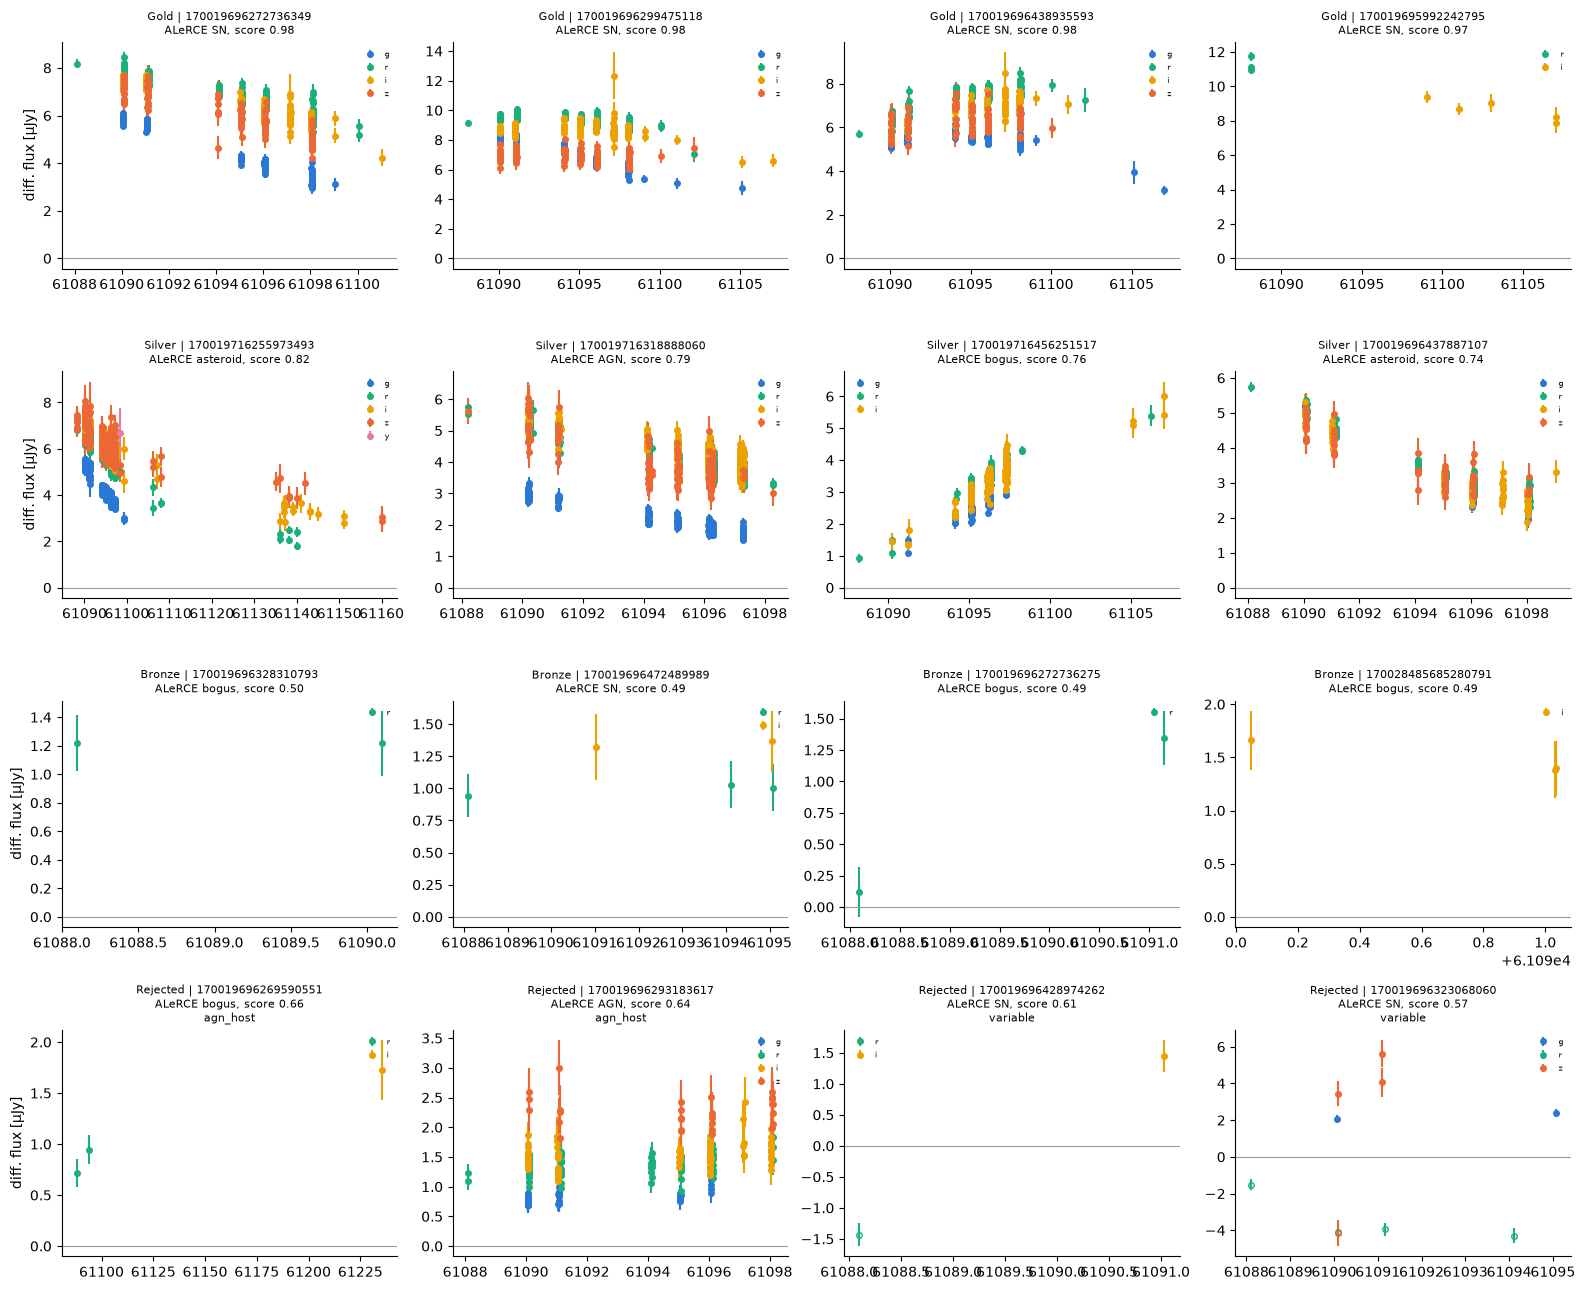

In [27]:
band_names = {1: "g", 2: "r", 3: "i", 4: "z", 5: "y", 6: "u"}
band_color = {1: "#2a78d6", 2: "#1baf7a", 3: "#eda100", 4: "#eb6834", 5: "#e87ba4", 6: "#6a4c93"}
n_show = 4
fig, axes = plt.subplots(len(tier_order), n_show, figsize=(16, 13))
for row, tier in zip(axes, tier_order):
    sample = feat[feat["tier"] == tier].sort_values("sn_score", ascending=False).head(n_show)
    for ax, (oid, r) in zip(row, sample.iterrows()):
        d = det[det["oid"] == oid]
        for b, db in d.groupby("band"):
            for neg, fill in [(False, band_color[b]), (True, "none")]:
                x = db[db["isnegative"] == neg]
                ax.errorbar(x["mjd"], x["psfflux"] / 1e3, x["psffluxerr"] / 1e3, fmt="o", ms=4,
                            color=band_color[b], mfc=fill, label=band_names[b] if not neg else None)
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set_title(f"{tier} | {oid}\nALeRCE {r['alerce_class']}, score {r['sn_score']:.2f}"
                     + (f"\n{r['veto_reason']}" if r["veto_reason"] else ""), fontsize=8)
        ax.legend(fontsize=6, frameon=False)
        ax.spines[["top", "right"]].set_visible(False)
    row[0].set_ylabel("diff. flux [µJy]")
plt.tight_layout()
plt.show()

## 2.9 Export
The ranked table (one row per object, with all features, `veto_reason`, `sn_score` and `tier`) is the input for the
host-matching step (`LSDB_matching.ipynb` / DELIGHT). Rejected objects are kept in the file so the decision can be
audited or the thresholds changed later.

In [28]:
out_cols = ["ra", "dec", "tier", "sn_score", "veto_reason", "alerce_class", "p_SN", "p_AGN", "p_bogus",
            "n_nights", "n_bands", "med_rel", "fp_frac_pos3", "frac_neg", "frac_dipole", "n_rev",
            "separationArcsec", "physical_separation_kpc", "z_best", "peak_mag", "abs_mag", "lum_flag", "w12",
            "catalogue_table_name", "tns_name", "tns_type"]
ranked = feat[out_cols].sort_values(["tier", "sn_score"], ascending=[True, False],
                                    key=lambda s: s.map({t: i for i, t in enumerate(tier_order)}) if s.name == "tier" else s)
ranked.to_csv("sn_candidates_ranked.csv", index_label="oid")
print(ranked["tier"].value_counts()[tier_order])
ranked.head(20)

tier
Gold         54
Silver      198
Bronze      241
Rejected    507
Name: count, dtype: int64


,ra,dec,tier,sn_score,veto_reason,alerce_class,p_SN,p_AGN,p_bogus,n_nights,n_bands,med_rel,fp_frac_pos3,frac_neg,frac_dipole,n_rev,separationArcsec,physical_separation_kpc,z_best,peak_mag,abs_mag,lum_flag,w12,catalogue_table_name,tns_name,tns_type
oid,,,,,,,,,,,,,,,,,,,,,,,,,,
170019696272736349,61.497111,-49.245787,Gold,0.984709,,SN,0.984013,0.003316,0.001138,11,4,0.974015,0.975610,0.0,0.0,0.0,1.564,NaN,NaN,21.582315,NaN,,NaN,DESI,2026fku,
170019696299475118,60.150586,-48.419644,Gold,0.982057,,SN,0.939849,0.010425,0.002386,14,4,0.999060,0.989130,0.0,0.0,0.0,0.709,NaN,NaN,21.172392,NaN,,NaN,DESI,2026fgr,
170019696438935593,62.952948,-47.749221,Gold,0.980949,,SN,0.961168,0.015453,0.002722,14,4,0.979324,0.979167,0.0,0.0,0.0,0.703,NaN,NaN,21.580326,NaN,,0.019,DESI,2026fep,
170019695992242795,52.823855,-29.691604,Gold,0.971111,,SN,0.991934,0.002390,0.000844,5,2,0.948970,1.000000,0.0,0.0,0.0,3.138,6.290,0.109912,21.226940,-17.379664,,NaN,NED,2026jvd,
170019716316790837,151.548578,1.453601,Gold,0.964962,,SN,0.984521,0.004931,0.001654,15,4,0.892598,0.961250,0.0,0.0,0.0,56.796,36.847,0.032500,22.024509,-13.820192,too_faint_for_host_z,-0.190,SDSS,2026euu,
170019696466198671,61.851091,-47.356485,Gold,0.961308,,SN,0.920890,0.045441,0.003711,10,4,0.950300,0.964103,0.0,0.0,0.0,0.514,NaN,NaN,21.742722,NaN,,0.110,DESI,NaN,NaN
170019696266444924,59.899046,-50.459673,Gold,0.955944,,SN,0.954770,0.017181,0.003200,11,4,0.873520,0.970190,0.0,0.0,0.0,0.910,NaN,NaN,22.248602,NaN,,0.368,DESI,2026jko,
170019716335140929,149.857915,3.521091,Gold,0.950771,,SN,0.862286,0.046839,0.005344,12,4,0.972848,0.972921,0.0,0.0,0.0,0.487,NaN,0.543208,21.960480,-20.582072,,NaN,SDSS/DESI/PS1,2026eib,
170019696345088120,58.086446,-48.019421,Gold,0.948847,,SN,0.883001,0.058105,0.004422,13,4,0.998951,0.970027,0.0,0.0,0.0,0.429,NaN,NaN,21.190258,NaN,,NaN,DESI,2026fgs,


## 2.10 Limitations and next steps
* **Short baseline.** All objects have ≤ ~3 weeks of data, so we cannot yet use the full light-curve shape
  (rise time, decline rate, colour evolution). Re-running this notebook in a few weeks will make `n_rev`, `n_nights`
  and `fp_frac_pos3` much more powerful, and ALeRCE may start publishing its light-curve classifier for LSST
  (today `lc_classifier_BHRF_*` exists only for ZTF, `tid = 0`).
* **Weights and thresholds are not fitted.** Once some objects have TNS spectra (or after visual inspection of a
  sample), the thresholds can be checked: what fraction of real SNe survive each veto (should be ~100 %).
* **Redshifts** exist for only a few percent of the hosts, and several of them belong to a wrong (foreground)
  host. Once DELIGHT gives the correct host and a photo-z, the luminosity test (−14 > M > −23) can become a real
  veto.
* **Nuclear transients.** Many Lasair "SN" sit < 0.5″ from the host centre. Without extra information they stay
  in Bronze/Silver. They could be AGN flares, TDEs or nuclear SNe; the host matching will at least tell us the host.